# Create a synthetic sitar and tabla mixture

The sitar and tabla files are separate performances, not aligned stems from the same original performance. This notebook combines them synthetically for a basic demonstration. It is not a benchmark of real-world source separation quality.

The original recordings are only read. The notebook saves just the mixture to `outputs/synthetic_mixture.wav`.

## Import libraries and find the project folder

We use `soundfile` to read and write audio, NumPy for signal operations, and Matplotlib for plots. The project root is found by looking for its `data` folder, so these paths work whether Jupyter starts in the project root or in `notebooks`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    import soundfile as sf
except ImportError as error:
    raise ImportError("Install the soundfile package in the selected Python environment to use this notebook.") from error

root_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (candidate for candidate in root_candidates if (candidate / "data").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root containing the data folder.")

sitar_path = PROJECT_ROOT / "data" / "Sohini_Qawwali.ogg"
tabla_path = PROJECT_ROOT / "data" / "Tabla_drums_demo.oga"
output_path = PROJECT_ROOT / "outputs" / "synthetic_mixture.wav"

print(f"Project root: {PROJECT_ROOT}")

Project root: d:\indian-instrument-separation


## Load both recordings

Audio is loaded as floating-point samples with channels kept as separate columns. A missing file or an audio decoding problem stops the notebook with the file name and a clear error.

In [2]:
try:
    sitar_stereo, sitar_sample_rate = sf.read(sitar_path, dtype="float64", always_2d=True)
except FileNotFoundError as error:
    raise FileNotFoundError(f"Sitar recording not found: {sitar_path}") from error
except Exception as error:
    raise RuntimeError(f"Could not read sitar recording '{sitar_path}': {error}") from error

try:
    tabla_stereo, tabla_sample_rate = sf.read(tabla_path, dtype="float64", always_2d=True)
except FileNotFoundError as error:
    raise FileNotFoundError(f"Tabla recording not found: {tabla_path}") from error
except Exception as error:
    raise RuntimeError(f"Could not read tabla recording '{tabla_path}': {error}") from error

print(f"Sitar sample rate: {sitar_sample_rate} Hz")
print(f"Tabla sample rate: {tabla_sample_rate} Hz")

Sitar sample rate: 44100 Hz
Tabla sample rate: 44100 Hz


## Check sample rates, convert to mono, and trim

The sample rates must match; this notebook stops rather than resampling either source. Each file is required to have two channels, which are averaged to make one mono signal. Then both signals are trimmed to the shorter sample count so they have equal lengths.

In [3]:
if sitar_sample_rate != tabla_sample_rate:
    raise ValueError(
        f"Sample rates do not match ({sitar_sample_rate} Hz and {tabla_sample_rate} Hz). "
        "The notebook will not resample either recording."
    )

if sitar_stereo.shape[1] != 2:
    raise ValueError(f"Expected 2 sitar channels, found {sitar_stereo.shape[1]}.")
if tabla_stereo.shape[1] != 2:
    raise ValueError(f"Expected 2 tabla channels, found {tabla_stereo.shape[1]}.")
if sitar_stereo.shape[0] == 0 or tabla_stereo.shape[0] == 0:
    raise ValueError("One of the recordings contains no audio samples.")
if not np.isfinite(sitar_stereo).all() or not np.isfinite(tabla_stereo).all():
    raise ValueError("One of the recordings contains NaN or infinite values.")

sitar_mono = sitar_stereo.mean(axis=1)
tabla_mono = tabla_stereo.mean(axis=1)

number_of_samples = min(len(sitar_mono), len(tabla_mono))
sitar_mono = sitar_mono[:number_of_samples]
tabla_mono = tabla_mono[:number_of_samples]
sample_rate = sitar_sample_rate

print(f"Trimmed length: {number_of_samples} samples ({number_of_samples / sample_rate:.2f} seconds)")

Trimmed length: 6912531 samples (156.75 seconds)


## Normalize and combine with equal contribution

Peak normalization scales each non-silent recording to a maximum absolute amplitude of 0.95, leaving headroom. The normalized signals are then averaged, giving each equal gain contribution. A final safety check scales the mixture only if its peak exceeds 0.99.

In [4]:
def normalize_peak(signal, target_peak=0.95):
    peak = np.max(np.abs(signal))
    if peak == 0:
        return signal.copy()
    return signal * (target_peak / peak)


sitar_normalized = normalize_peak(sitar_mono)
tabla_normalized = normalize_peak(tabla_mono)
mixture = 0.5 * sitar_normalized + 0.5 * tabla_normalized

mixture_peak = np.max(np.abs(mixture))
if mixture_peak > 0.99:
    mixture = mixture * (0.99 / mixture_peak)

## Save the mixture and print signal details

Only the synthetic mixture is saved. The sample count and duration are the same for all three trimmed signals. Peak amplitude is the largest absolute sample value before saving.

In [5]:
output_path.parent.mkdir(parents=True, exist_ok=True)
sf.write(output_path, mixture, sample_rate, subtype="PCM_16")
print(f"Saved mixture: {output_path}")

signals = {
    "Sitar (mono, normalized)": sitar_normalized,
    "Tabla (mono, normalized)": tabla_normalized,
    "Synthetic mixture": mixture,
}

for name, signal in signals.items():
    duration = len(signal) / sample_rate
    peak_amplitude = np.max(np.abs(signal))
    print(
        f"{name}: sample rate={sample_rate} Hz, duration={duration:.2f} seconds, "
        f"samples={len(signal)}, peak amplitude={peak_amplitude:.6f}"
    )

Saved mixture: d:\indian-instrument-separation\outputs\synthetic_mixture.wav
Sitar (mono, normalized): sample rate=44100 Hz, duration=156.75 seconds, samples=6912531, peak amplitude=0.950000
Tabla (mono, normalized): sample rate=44100 Hz, duration=156.75 seconds, samples=6912531, peak amplitude=0.950000
Synthetic mixture: sample rate=44100 Hz, duration=156.75 seconds, samples=6912531, peak amplitude=0.575369


## Plot the first five seconds

Each waveform is plotted separately against time in seconds. If the recordings are shorter than five seconds, the plot uses their full available duration.

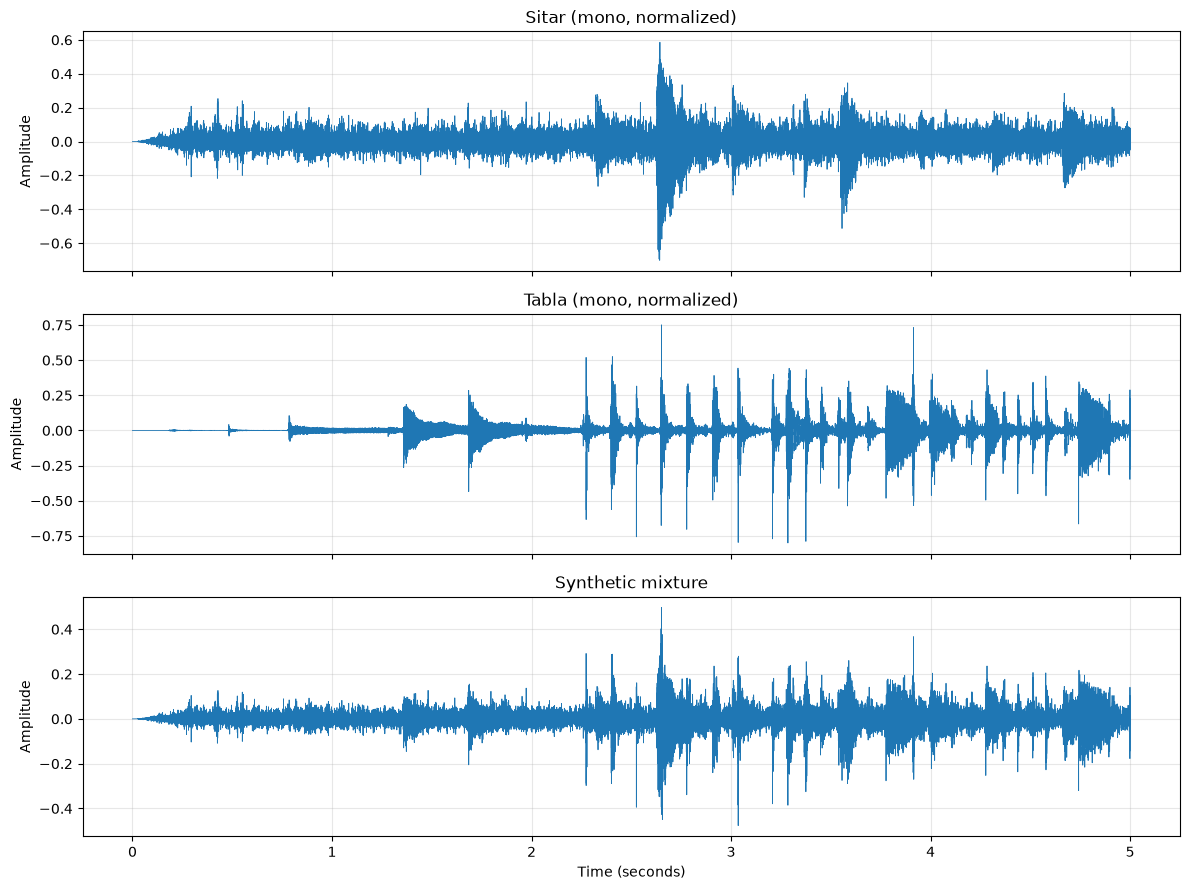

In [6]:
plot_samples = min(5 * sample_rate, number_of_samples)
time_seconds = np.arange(plot_samples) / sample_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
plot_signals = [
    ("Sitar (mono, normalized)", sitar_normalized),
    ("Tabla (mono, normalized)", tabla_normalized),
    ("Synthetic mixture", mixture),
]

for axis, (name, signal) in zip(axes, plot_signals):
    axis.plot(time_seconds, signal[:plot_samples], linewidth=0.6)
    axis.set_title(name)
    axis.set_ylabel("Amplitude")
    axis.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.tight_layout()
plt.show()